<a href="https://colab.research.google.com/github/SaraEstilaei/DigiSmart_Assistant/blob/P3%2F-Baseline(TF-IDF)/Baseline_recommendation_status_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl">

# Part 3 — Baseline: پیش‌بینی `recommendation_status` (TF-IDF + مدل‌های خطی)

**هدف:** از روی *متن* یک نظر، یکی از سه کلاس `recommended` / `not_recommended` / `no_idea` را پیش‌بینی کنیم. معیار اصلی: **Macro F1**.

**پروتکل (قابل دفاع در ارائه):**
1. ورودی فقط متن است: `title + body + advantages + disadvantages` (ستون `rate` و بقیه‌ی ستون‌ها وارد مدل نمی‌شوند).
2. تقسیم داده **بر اساس `product_id`** (`StratifiedGroupKFold`) تا هیچ محصولی هم در train و هم در test نباشد، با حفظ نسبت کلاس‌ها.
3. هیچ متن یکسانی در دو بخش مختلف نیست (حذف هم‌پوشانی متنی از train/val نسبت به test).
4. همه‌ی انتخاب‌ها (نوع ویژگی، `C`، مدل، bias کلاس‌ها) فقط روی **validation**؛ **test فقط یک‌بار** برای مدل نهایی.
5. Splitها در فایل ذخیره می‌شوند تا ParsBERT / FaBERT / XLM-R دقیقاً روی همان داده اجرا شوند.
6. **دو حالت اجرا (`RUN_ON`):** `"compare"` (پیش‌فرض) = زیرمجموعه‌ی ~۸۰۰۰ نظری فقط برای مقایسه‌ی سریع مدل‌ها؛ `"full"` = کل داده برای Baseline نهایی. زیرمجموعه فقط از train کامل برداشته می‌شود، پس test کامل دست‌نخورده می‌ماند.

**خروجی‌ها:** جدول مقایسه‌ی مدل‌ها، Macro F1 تست با بازه‌ی اطمینان، confusion matrix، تحلیل خطا، تابع `predict_recommendation(text)`، فایل Split.

<div dir="rtl">

## ۰) تنظیمات و import ها

In [25]:
import os, sys, re, json, time, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings("ignore", category=FutureWarning)

# ------------------------- Config -------------------------
SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 220)

DATA_SOURCE = "gdown"          # "gdown" | "drive" | "local"
COMMENTS_GDRIVE_ID = "1xzTsavJ5HPRJAP6CD7_Z6Ya1_Qw6o3sQ"   # 15k comments (parquet)
PRODUCTS_GDRIVE_ID = "15hznYy0hGbXG123kHoBVVIcBVA8dLZYF"   # products_clean.zip
DRIVE_COMMENTS_PATH = "/content/drive/MyDrive/QBC13_final/comments_sample.parquet"   # for DATA_SOURCE="drive"
DRIVE_PRODUCTS_PATH = "/content/drive/MyDrive/QBC13_final/products_sample.parquet"
LOCAL_COMMENTS_PATH = "comments_sample.parquet"                                       # for DATA_SOURCE="local"
LOCAL_PRODUCTS_PATH = "products_sample.parquet"

PERSIST_TO_DRIVE = True        # in Colab: save outputs to Google Drive so they survive runtime resets
QUICK = False                  # True => tiny grids, for a fast smoke test only
STRICT_TEXT_DEDUP = True       # no identical text may appear in two different splits
N_FOLDS = 7                    # 1 fold -> test (~14%), 1 fold -> val (~14%), 5 folds -> train (~72%)
RUN_ON = "full"             # "compare": ~8000-comment screening subset (fast, default) | "full": all data (final baseline)
CMP_N = 8000                   # size of the comparison subset (drawn ONLY from the full TRAIN part -> the full test set is never touched)
CMP_N_FOLDS = 5                # inside the subset: 1 fold -> test (20%), 1 -> val (20%), 3 -> train (60%)
BIAS_MIN_GAIN = None if RUN_ON == "compare" else 0.01   # class-bias tuning: OFF for the small comparison runs (too noisy), ON for the full run
N_BOOT = 1000                  # bootstrap resamples (clustered by product) for the test CI
RUN_LEARNING_CURVE = True

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and (PERSIST_TO_DRIVE or DATA_SOURCE == "drive"):
    from google.colab import drive
    drive.mount("/content/drive")
if IN_COLAB and PERSIST_TO_DRIVE:
    WORK_DIR = Path("/content/drive/MyDrive/QBC13_final/part3_classifier")
else:
    WORK_DIR = Path("qbc13_part3")

assert RUN_ON in ("compare", "full"), "RUN_ON must be 'compare' or 'full'"
RAW_DIR, SRC_DIR, SPLIT_DIR = (WORK_DIR / d for d in ("raw", "src", "splits"))
OUT_DIR = WORK_DIR / f"outputs_{RUN_ON}"
MODEL_DIR = WORK_DIR / "models" / RUN_ON
for d in (RAW_DIR, SRC_DIR, OUT_DIR, MODEL_DIR, SPLIT_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("WORK_DIR =", WORK_DIR.resolve())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
WORK_DIR = /content/drive/MyDrive/QBC13_final/part3_classifier


## ۱) بارگذاری داده

In [26]:
import zipfile

def _check_not_html(path):
    with open(path, "rb") as f:
        head = f.read(200).lstrip().lower()
    if head.startswith(b"<!doctype html") or head.startswith(b"<html"):
        raise RuntimeError(
            f"{path} is an HTML page, not a data file. "
            "Check Drive sharing = 'Anyone with the link', or use DATA_SOURCE='drive'."
        )

def _gdown_raw(file_id, out_path):
    import gdown
    out_path = Path(out_path)
    if not out_path.exists():
        gdown.download(f"https://drive.google.com/uc?id={file_id}", str(out_path), quiet=False)
    try:
        _check_not_html(out_path)
    except RuntimeError:
        out_path.unlink(missing_ok=True)
        raise
    return out_path

def _read_table(path):
    path = Path(path)
    with open(path, "rb") as f:
        head = f.read(4)
    if head == b"PAR1":
        return pd.read_parquet(path)
    if zipfile.is_zipfile(path):
        extract_dir = RAW_DIR / f"{path.stem}_extracted"
        extract_dir.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(path, "r") as zf:
            zf.extractall(extract_dir)
        files = [
            p for p in extract_dir.rglob("*")
            if p.is_file() and "__MACOSX" not in p.parts and not p.name.startswith("._")
        ]
        parquets = [p for p in files if p.suffix.lower() == ".parquet"]
        csvs = [p for p in files if p.suffix.lower() == ".csv"]
        if parquets:
            print("Loaded from zip:", parquets[0].name)
            return pd.read_parquet(parquets[0])
        if csvs:
            print("Loaded from zip:", csvs[0].name)
            return pd.read_csv(csvs[0])
        raise RuntimeError(f"No .parquet or .csv found inside {path}. Contents: {[p.name for p in files]}")
    if path.suffix.lower() == ".csv":
        return pd.read_csv(path)
    raise RuntimeError(f"Unsupported or corrupted file format: {path}")

if DATA_SOURCE == "gdown":
    c_path = _gdown_raw(COMMENTS_GDRIVE_ID, RAW_DIR / "comments_15k.parquet")
    p_path = _gdown_raw(PRODUCTS_GDRIVE_ID, RAW_DIR / "products_clean.zip")
elif DATA_SOURCE == "drive":
    c_path, p_path = Path(DRIVE_COMMENTS_PATH), Path(DRIVE_PRODUCTS_PATH)
else:
    c_path, p_path = Path(LOCAL_COMMENTS_PATH), Path(LOCAL_PRODUCTS_PATH)

comments = _read_table(c_path)
products = _read_table(p_path)
print("comments:", comments.shape, "| products:", products.shape)

Loaded from zip: products_clean.parquet
comments: (15000, 12) | products: (948352, 15)


<div dir="rtl">

## ۲) ماژول پیش‌پردازش متن فارسی (یک منبع واحد برای همه‌ی نوت‌بوک‌ها)
این سلول فایل `src/persian_text.py` را می‌نویسد. بقیه‌ی اعضای تیم می‌توانند همین فایل را import کنند تا **همه‌ی مدل‌ها یک پیش‌پردازش یکسان** داشته باشند. :>

تصمیم‌های پیش‌پردازش:
- `NFKC` + یکسان‌سازی حروف عربی/فارسی (`ي به ی`, `ك به ک`, ...) و ارقام فارسی/عربی به لاتین
- حذف اعراب، کشیده (ـ) و کاراکترهای نامرئی؛ حذف URL
- حروف تکراری (۳ بار یا بیشتر) → یک بار (`عاااالی به عالی`)؛ ارقام دست‌نخورده (تا `1000000` خراب نشود)
- **نیم‌فاصله در متن ذخیره‌شده حفظ می‌شود** (برای توکنایزر BERT مفید است) ولی فقط برای TF-IDF به فاصله تبدیل می‌شود
- ایموجی‌ها حذف نمی‌شوند (ممکن است سیگنال احساسی باشند)
</div>


In [27]:
PERSIAN_TEXT_SRC = r'''
import ast
import re
import unicodedata

import numpy as np

LABELS = ["recommended", "not_recommended", "no_idea"]
ZWNJ = "\u200c"

_CHAR_MAP = str.maketrans({"ي": "ی", "ى": "ی", "ك": "ک", "ة": "ه", "أ": "ا", "إ": "ا", "ٱ": "ا"})
_DIGIT_MAP = str.maketrans("۰۱۲۳۴۵۶۷۸۹٠١٢٣٤٥٦٧٨٩", "01234567890123456789")
_DIACRITICS = re.compile("[\u064b-\u065f\u0670\u0640]")
_INVISIBLE = re.compile("[\u200b\u200d\u200e\u200f\u202a-\u202e\u2066-\u2069\ufeff]")
_URL = re.compile(r"(https?://\S+|www\.\S+)")
_REPEAT = re.compile(r"([^\d\s])\1{2,}")
_SPACES = re.compile(r"\s+")
_NULLS = {"none", "nan", "null", "<na>", "nat", "[]"}


def normalize_label(x):
    if x is None:
        return None
    s = str(x).strip().lower().replace(" ", "_").replace("-", "_")
    return s if s in LABELS else None


def to_str(x):
    if x is None:
        return ""
    if isinstance(x, (list, tuple, set, np.ndarray)):
        parts = [to_str(i) for i in x]
        return " ، ".join(p for p in parts if p)
    if isinstance(x, float) and x != x:
        return ""
    s = str(x).strip()
    if s.lower() in _NULLS:
        return ""
    if s.startswith("[") and s.endswith("]"):
        try:
            v = ast.literal_eval(s)
            if isinstance(v, (list, tuple)):
                return to_str(list(v))
        except Exception:
            pass
    return s


def clean_text(x):
    s = to_str(x)
    if not s:
        return ""
    s = unicodedata.normalize("NFKC", s)
    s = s.translate(_CHAR_MAP).translate(_DIGIT_MAP)
    s = _URL.sub(" ", s)
    s = _DIACRITICS.sub("", s)
    s = _INVISIBLE.sub("", s)
    s = _REPEAT.sub(r"\1", s)
    s = _SPACES.sub(" ", s).strip()
    return s


def build_text(title=None, body=None, advantages=None, disadvantages=None):
    t, b = clean_text(title), clean_text(body)
    a, d = clean_text(advantages), clean_text(disadvantages)
    parts = []
    if t:
        parts.append(t)
    if b and b != t:
        parts.append(b)
    if a:
        parts.append("مزایا: " + a)
    if d:
        parts.append("معایب: " + d)
    return " . ".join(parts)


def tfidf_preprocess(s):
    # used only by TF-IDF: lowercase latin + ZWNJ -> space (so "می‌خوام" == "می خوام")
    return s.lower().replace(ZWNJ, " ")
'''
(SRC_DIR / "persian_text.py").write_text(PERSIAN_TEXT_SRC, encoding="utf-8")

if str(SRC_DIR.resolve()) not in sys.path:
    sys.path.insert(0, str(SRC_DIR.resolve()))
import importlib, persian_text
importlib.reload(persian_text)
from persian_text import LABELS, normalize_label, to_str, clean_text, build_text, tfidf_preprocess

# ---- unit tests ----
assert clean_text("عاااالی!!!") == "عالی!"
assert clean_text("كتاب ي خوب") == "کتاب ی خوب"
assert clean_text("قیمت ۱۰۰۰۰۰۰ تومان") == "قیمت 1000000 تومان"
assert clean_text(None) == "" and clean_text(float("nan")) == "" and clean_text("None") == ""
assert clean_text(["خوب", "ارزان"]) == "خوب ، ارزان"
assert clean_text("سلام   \n  دنیا") == "سلام دنیا"
assert tfidf_preprocess("می\u200cخوام") == "می خوام"
assert build_text("عالی", "عالی", None, "گرون") == "عالی . معایب: گرون"
print("persian_text.py written and unit tests passed ->", SRC_DIR / "persian_text.py")

persian_text.py written and unit tests passed -> /content/drive/MyDrive/QBC13_final/part3_classifier/src/persian_text.py


<div dir="rtl">


## ۳) ممیزی داده (Data Audit)
قبل از هر تصمیمی، داده را می‌بینیم. خروجی این سلول‌ها مستقیماً به بخش «کیفیت داده» گزارش می‌رود.

In [28]:
print("Columns:", list(comments.columns))
display(comments.head(3))
print()
print("Dtypes:"); print(comments.dtypes.to_string())

nulls = comments.isna().mean().mul(100).round(2).sort_values(ascending=False)
print("\nNull % per column (only >0):")
display(nulls[nulls > 0].to_frame("null_%"))

print("Is 'id' unique? ", comments["id"].is_unique if "id" in comments else "no id column")
print("Raw recommendation_status values:")
display(comments["recommendation_status"].value_counts(dropna=False).to_frame("count")
        .assign(pct=lambda d: (d["count"] / d["count"].sum() * 100).round(2)))

Columns: ['id', 'product_id', 'rate', 'created_date', 'body_persian_ratio', 'title', 'body', 'advantages', 'disadvantages', 'recommendation_status', 'likes', 'dislikes']


,id,product_id,rate,created_date,body_persian_ratio,title,body,advantages,disadvantages,recommendation_status,likes,dislikes
0,14144758,1075274,5.00,2020-11-30,0.818,هری پاتر,عالیه مخصوصا طرحش عکس مجموعه هری پاترم رو میزارم اگه خوشتون اومد لطفا لایک کنید که نظرم موندگار بشه,None,None,recommended,1136,8
1,29774764,6850623,4.00,2022-01-07,0.799,این مجله تبلیغاتی است و بایستی رایگان دست مشتریهای ثابت میرسید,این مجله را باید دیجی کالا باید رایگان به مشتری های ثابت و قدیمی ارسال می کرد تا اطلاعات مشتری کامل تر بشود ولی متأس...,None,None,recommended,414,6
2,16583783,268428,2.75,2021-01-28,0.787,در صورت قصد خرید مطالعه شود,محصول با کیفیت و کار بردی‌ایه ، بسته بندی خاصی نداره یه برگه کاغذی توشه که یه سری توضیحات در مورد محصول نوشته شده و ...,None,None,recommended,394,2



Dtypes:
id                                int64
product_id                        int64
rate                            float64
created_date             datetime64[ns]
body_persian_ratio              float32
title                            object
body                             object
advantages                       object
disadvantages                    object
recommendation_status            object
likes                             int64
dislikes                          int64

Null % per column (only >0):


,null_%
disadvantages,77.98
advantages,63.73
rate,13.31


Is 'id' unique?  True
Raw recommendation_status values:


,count,pct
recommendation_status,,
recommended,11908,79.39
not_recommended,1587,10.58
no_idea,1505,10.03


In [29]:
# What do the text fields look like? (types / samples)
for col in ["title", "body", "advantages", "disadvantages"]:
    if col in comments.columns:
        nn = comments[col].dropna()
        print(f"--- {col}: non-null={len(nn)} ({len(nn)/len(comments)*100:.1f}%), python types={nn.map(type).value_counts().to_dict()}")
        print(nn.head(3).tolist())
    else:
        print(f"--- {col}: NOT in columns")

--- title: non-null=15000 (100.0%), python types={<class 'str'>: 15000}
['هری پاتر', 'این مجله تبلیغاتی است و بایستی رایگان دست مشتریهای ثابت میرسید', 'در صورت قصد خرید مطالعه شود']
--- body: non-null=15000 (100.0%), python types={<class 'str'>: 15000}
['عالیه مخصوصا طرحش عکس مجموعه هری پاترم رو میزارم اگه خوشتون اومد لطفا لایک کنید که نظرم موندگار بشه', 'این مجله را باید دیجی کالا باید رایگان به مشتری های ثابت و قدیمی ارسال می کرد تا اطلاعات مشتری کامل تر بشود ولی متأسفانه فروشی ارائه می شود', 'محصول با کیفیت و کار بردی\u200cایه ، بسته بندی خاصی نداره یه برگه کاغذی توشه که یه سری توضیحات در مورد محصول نوشته شده و محصول توی یه کاور پلاستیکیه معمولی ارسال شده ، توی چند هفته ای که خریدمش چندین بار ازش استفاده کردم ، کافیه 1 دقیقه الی نهایت یک دقیقه و نیم توی ماکروفر قرارش بدید ، بعد برش دارید و یه کم بمالیدش تا تمام مواد داخلش پخش بشه ، حالا آمادست برای استفاده ، حدود نیم ساعت گرمای مطلوبی رو بهتون میده و اروم اروم شروع به از دست دادن دما میکنه ، مواد بکار رفته داخلش حالت ژلاتینی داره و 

rate x recommendation_status (row-normalised %):


recommendation_status,no_idea,not_recommended,recommended
rate,,,
0.05,50.0,50.0,0.0
0.20,0.0,100.0,0.0
0.25,0.0,40.0,60.0
0.30,0.0,100.0,0.0
0.40,0.0,100.0,0.0
...,...,...,...
4.75,0.9,0.0,99.1
4.80,0.0,0.0,100.0
4.85,0.0,0.0,100.0



body length (words) per class:


,count,mean,std,min,25%,50%,75%,max
recommendation_status,,,,,,,,
no_idea,1505.0,61.3,70.0,2.0,20.0,40.0,76.0,853.0
not_recommended,1587.0,53.0,55.0,1.0,20.0,36.0,66.5,623.0
recommended,11908.0,43.4,63.4,1.0,10.0,23.0,49.0,862.0



Top-10 most frequent bodies and their label distribution:


recommendation_status,no_idea,recommended
body,,
خوب بود,0,17
خیلی خوب بود,1,10
خیلی عالی بود,0,8
عالی,0,21
عالی بود,0,13
عالی و فوق العاده و کاملا راضیم این کتاب امروز سالم و بسته بندی عالی به دستم رسید. کاغذ سفید مرغوب خارجی درجه یک داره. فونت و صفحه آرایی قوی و خوبی داره چند ص از کتاب رو مطالعه کردم. ترجمه فوق العاده داره. نسبت به تخفیفی که خورده فتوکپی بخوایم بگیریم ارزونتر در میاد. جلد مقوایی با کیفیت داره و چاپ و طراحی ظاهریش عالیه. چاپ داخلش تمیز و یکدست و بدون ایراده. کتاب سبک وزن هست و دست رو خسته نمیکنه. از خریدم کامل راضی هستم. برای کادو دادن از همه لحاظ مناسب و شایسته هستش. جزو معدود خریدهایی هست که رضایت 100 درصد دارم. از دیجی کالا هم به خاطر تخفیف های خوب و ارسال به موقع و حمایت 100 درصدی از قشر کتابخون تو این وضعیت اقتصادی تشکر میکنم.,0,7
عالیی,0,14
قیمت / ترجمه / صحافی / طرح جلد / کاغذ همه چی عالی هستش !! DigiKala Is Number 1,0,7
مجموعه عاشقانه‌های کلاسیک نشر افق یک مجموعه رمان هفده جلدیه که علاوه بر داستان بسیار زیبا از نویسندگان برتر دنیا دارای طراحی جلد منحصر به فردیه که آدمو شیفته خودش میکنه ؛) به شدت به عاشقان کتاب پیشنهاد میکنم این مجموعه زیبا رو خریداری کنید با تخفیف‌های خوب دیجی کالا. عکس این مجموعه را آپلود کردم مشاهده کنید.,0,7


Exact-duplicate body rate: 2.03%

comments per product:


,count,mean,std,min,25%,50%,75%,max
value,8872.0,1.7,2.4,1.0,1.0,1.0,2.0,65.0


share of comments from top-1% products: 11.8%

created_date range: 2016-07-23 00:00:00 -> 2023-10-09 00:00:00
comments with Persian ratio < 0.3: 0.01%


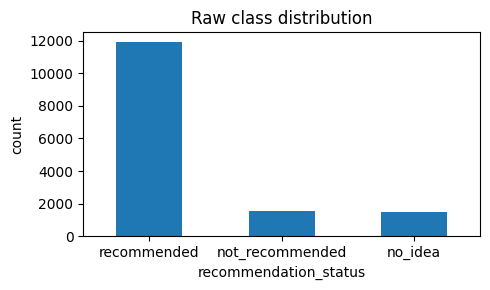

In [30]:
# Relationship between label and rate (diagnostic only; rate is NOT a model feature)
if "rate" in comments.columns:
    print("rate x recommendation_status (row-normalised %):")
    display((pd.crosstab(comments["rate"], comments["recommendation_status"], normalize="index") * 100).round(1))

# Text length per class
tmp = comments.copy()
tmp["n_words"] = tmp["body"].map(to_str).str.split().str.len()
print("\nbody length (words) per class:")
display(tmp.groupby("recommendation_status")["n_words"].describe().round(1))

# Most frequent bodies (generic phrases are a leakage / duplication risk)
top_bodies = tmp["body"].map(clean_text).value_counts().head(10).index
print("\nTop-10 most frequent bodies and their label distribution:")
display(pd.crosstab(tmp["body"].map(clean_text)[tmp["body"].map(clean_text).isin(top_bodies)],
                    tmp["recommendation_status"]))
print("Exact-duplicate body rate: %.2f%%" % (tmp["body"].map(clean_text).duplicated().mean() * 100))

# Product groups (why we must split by product)
vc = comments["product_id"].value_counts()
print("\ncomments per product:"); display(vc.describe().round(1).to_frame("value").T)
print("share of comments from top-1%% products: %.1f%%" % (vc.head(max(1, int(len(vc) * 0.01))).sum() / vc.sum() * 100))

if "created_date" in comments.columns:
    d = pd.to_datetime(comments["created_date"], errors="coerce")
    print("\ncreated_date range:", d.min(), "->", d.max())
if "body_persian_ratio" in comments.columns:
    print("comments with Persian ratio < 0.3: %.2f%%" % ((comments["body_persian_ratio"] < 0.3).mean() * 100))

# Class distribution plot
ax = comments["recommendation_status"].value_counts().plot.bar(rot=0, figsize=(5, 3))
ax.set_title("Raw class distribution"); ax.set_ylabel("count"); plt.tight_layout(); plt.show()

<div dir="rtl">



## ۴) پاک‌سازی و ساخت متن ورودی
تصمیم‌ها (هر خط یک ردیف در جدول لاگ ثبت می‌شود):
- برچسب نامعتبر/خالی حذف می‌شود.
- متن = `title . body . مزایا: ... . معایب: ...` (فقط فیلدهای غیرخالی).
- متن خالی بعد از پاک‌سازی حذف می‌شود.
- تکراری‌های دقیق **داخل یک محصول** (همان `product_id` + همان متن + همان برچسب، مثل ثبت دوباره‌ی یک نظر) حذف می‌شود. تکراری‌های بین محصولات (مثل «عالی») نگه داشته می‌شوند چون در دنیای واقعی هم هستند؛ هم‌پوشانی بین splitها در مرحله‌ی بعد کنترل می‌شود.
- نظرهای کوتاه و غیرفارسی **حذف نمی‌شوند** (فقط گزارش می‌شوند) تا Test توزیع طبیعی داشته باشد.

In [31]:
df = comments.copy()
log = []
def step(name, d):
    log.append({"step": name, "rows": len(d), "products": d["product_id"].nunique()})

step("raw", df)

# --- labels
df["label"] = df["recommendation_status"].map(normalize_label)
n_bad = df["label"].isna().sum()
df = df[df["label"].notna()].copy()
step(f"drop invalid/missing label ({n_bad} rows)", df)

# --- text
def col(name):
    return df[name] if name in df.columns else pd.Series([None] * len(df), index=df.index)

df["text"] = [build_text(t, b, a, d) for t, b, a, d in
              zip(col("title"), col("body"), col("advantages"), col("disadvantages"))]
# variants used only for the field-ablation experiment
df["text_body"] = [build_text(None, b) for b in col("body")]
df["text_title_body"] = [build_text(t, b) for t, b in zip(col("title"), col("body"))]

n_empty = (df["text"] == "").sum()
df = df[df["text"] != ""].copy()
step(f"drop empty text ({n_empty} rows)", df)

n_dup = df.duplicated(subset=["product_id", "text", "label"]).sum()
df = df.drop_duplicates(subset=["product_id", "text", "label"], keep="first").copy()
step(f"drop duplicate (product, text, label) ({n_dup} rows)", df)

# --- product_id must be usable as group key
df["product_id"] = pd.to_numeric(df["product_id"], errors="coerce")
n_pid = df["product_id"].isna().sum()
df = df[df["product_id"].notna()].copy()
df["product_id"] = df["product_id"].astype("int64")
step(f"drop rows without product_id ({n_pid} rows)", df)

df = df.reset_index(drop=True)
display(pd.DataFrame(log))

# sanity checks
assert df["id"].is_unique, "comment ids are not unique!"
idem = (df["text"].map(clean_text) == df["text"]).mean()
print("clean_text idempotent on built texts: %.4f" % idem)
df["n_words"] = df["text"].str.split().str.len()
print("short texts (<=2 words): %.1f%% | median words: %d" % ((df["n_words"] <= 2).mean() * 100, df["n_words"].median()))
print("\nClass distribution after cleaning:")
display(df["label"].value_counts().to_frame("count").assign(pct=lambda d: (d["count"] / d["count"].sum() * 100).round(2)))
display(df[["id", "product_id", "label", "text"]].sample(5, random_state=SEED))

,step,rows,products
0,raw,15000,8872
1,drop invalid/missing label (0 rows),15000,8872
2,drop empty text (0 rows),15000,8872
3,"drop duplicate (product, text, label) (0 rows)",15000,8872
4,drop rows without product_id (0 rows),15000,8872


clean_text idempotent on built texts: 1.0000
short texts (<=2 words): 0.2% | median words: 35

Class distribution after cleaning:


,count,pct
label,,
recommended,11908,79.39
not_recommended,1587,10.58
no_idea,1505,10.03


,id,product_id,label,text
11499,5064950,530317,recommended,کیفیت خیلی خوب . به شکل محسوسی هوا رو تصفیه و تمیز میکنه
6475,52617319,10389188,recommended,خیلی خوش دوخت و انداز بود . قیمت و دوختش خوبه از نظر من اگ دوست داشتید بخرید
13167,44577631,4170392,recommended,عالیه . خیلی زیبا و سرگرم کنندس برای بچه ها،دختر من چن ساعت ماهیگیری کرد و کلی ذوق کرد حتما بخرید
862,11497828,826979,recommended,خوبه . من برای دامادمان خریدم ازش خیلی راضی بود یه دختر مفتی بهش دادیم کمشه ؛ کفش هم میخوادبنابراین من2تاتوصیه دارم ...
5970,51842846,6302272,recommended,گ . واسه تمرین خیاطی خوبه


<div dir="rtl">


## ۵) اتصال اطلاعات محصول (فقط برای تحلیل خطا بر اساس دسته)
این اطلاعات **وارد مدل نمی‌شود**. اگر محصولات نمونه با `product_id` نظرها هم‌پوشانی نداشته باشند، `unknown` می‌شود و مشکلی پیش نمی‌آید.

In [32]:
prod = products.copy()
prod["pid"] = pd.to_numeric(prod["id"], errors="coerce")
keep_cols = [c for c in ["pid", "Category1", "Category2", "sub_category", "Brand"] if c in prod.columns]
prod = prod[keep_cols].dropna(subset=["pid"]).drop_duplicates("pid")
prod["pid"] = prod["pid"].astype("int64")

df = df.merge(prod.rename(columns={"pid": "product_id"}), on="product_id", how="left")
cov = df["sub_category"].notna().mean() * 100 if "sub_category" in df.columns else 0.0
print("comments matched to a product row: %.1f%%" % cov)
if "sub_category" not in df.columns:
    df["sub_category"] = np.nan
df["sub_category"] = df["sub_category"].fillna("unknown")
display(df["sub_category"].value_counts().head(10).to_frame("comments"))

comments matched to a product row: 100.0%


,comments
sub_category,
beauty,4892
clothe,3529
book & stationary & art,2753
toys and kids,2462
rural goods,931
travel,433


<div dir="rtl">


## ۶) تقسیم داده: Train / Val / Test بدون نشت (دو سطح)
**الف) Split کامل (برای مدل نهایی):** `StratifiedGroupKFold(7)` با گروه = `product_id` → ۷۲٪ train / ۱۴٪ val / ۱۴٪ test. ذخیره در `data_split_full.parquet`.

**ب) زیرمجموعه‌ی مقایسه:** فقط برای **غربالگری مدل‌ها** (Baseline، ParsBERT، FaBERT، XLM-R، ...) بدون هدر دادن GPU.
- فقط از **train کامل** برداشته می‌شود (نمونه‌گیری گروهی و طبقه‌ای: کل محصول‌ها با حفظ نسبت کلاس‌ها)؛ بنابراین **test کامل هیچ‌وقت در انتخاب مدل دخیل نیست**.
- داخل همین زیرمجموعه دوباره Split بدون نشت: ۶۰٪ / ۲۰٪ / ۲۰٪ (val و test بزرگ‌تر تا کلاس کم‌تعداد هم نمونه‌ی کافی داشته باشد). ذخیره در `data_split_compare.parquet`.

`RUN_ON` تعیین می‌کند ادامه‌ی نوت‌بوک روی کدام یک اجرا شود. **حذف هم‌پوشانی متنی** در هر دو سطح انجام می‌شود (Test دست نمی‌خورد).

In [33]:
from sklearn.model_selection import StratifiedGroupKFold

def make_split(d, n_folds, name=""):
    # product-disjoint, class-stratified train/val/test + removal of texts shared across splits
    d = d.reset_index(drop=True).copy()
    sgkf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=SEED)
    folds = [te for _, te in sgkf.split(d, d["label"].values, d["product_id"].values)]
    d["split"] = "train"
    d.loc[folds[1], "split"] = "val"
    d.loc[folds[0], "split"] = "test"
    print(f"[{name}] before text-overlap removal:", d["split"].value_counts().to_dict())
    if STRICT_TEXT_DEDUP:
        test_texts = set(d.loc[d["split"] == "test", "text"])
        val_texts = set(d.loc[d["split"] == "val", "text"])
        m_tr_te = (d["split"] == "train") & d["text"].isin(test_texts)
        m_va_te = (d["split"] == "val") & d["text"].isin(test_texts)
        m_tr_va = (d["split"] == "train") & d["text"].isin(val_texts) & ~m_tr_te
        print(f"[{name}] removed from train (text also in test): {m_tr_te.sum()} ({m_tr_te.sum()/max(1,(d.split=='train').sum())*100:.2f}% of train) | "
              f"from val (text also in test): {m_va_te.sum()} | from train (text also in val): {m_tr_va.sum()}")
        d = d[~(m_tr_te | m_va_te | m_tr_va)].reset_index(drop=True)
    return d

def assert_no_leakage(d, name=""):
    P = {s: set(d.loc[d.split == s, "product_id"]) for s in ("train", "val", "test")}
    I = {s: set(d.loc[d.split == s, "id"]) for s in ("train", "val", "test")}
    T = {s: set(d.loc[d.split == s, "text"]) for s in ("train", "val", "test")}
    assert not (P["train"] & P["val"]) and not (P["train"] & P["test"]) and not (P["val"] & P["test"]), f"[{name}] product leakage!"
    assert not (I["train"] & I["val"]) and not (I["train"] & I["test"]) and not (I["val"] & I["test"]), f"[{name}] id leakage!"
    if STRICT_TEXT_DEDUP:
        assert not (T["train"] & T["val"]) and not (T["train"] & T["test"]) and not (T["val"] & T["test"]), f"[{name}] text leakage!"
    for s in ("train", "val", "test"):
        assert set(d.loc[d.split == s, "label"]) == set(LABELS), f"[{name}] split {s} is missing a class"
    print(f"[{name}] OK: no product / id / text overlap between splits, all classes present in every split.")

def split_summary(d):
    g = d.groupby("split")
    s = pd.DataFrame({"rows": g.size(), "products": g["product_id"].nunique()})
    for l in LABELS:
        s[f"n_{l}"] = g["label"].apply(lambda x: int((x == l).sum()))
        s[f"%{l}"] = (g["label"].apply(lambda x: (x == l).mean()) * 100).round(2)
    return s.loc[["train", "val", "test"]]

# ---------------- (A) full split
df_full = make_split(df, N_FOLDS, name="full")
assert_no_leakage(df_full, "full")
SAVE_COLS = [c for c in ["id", "product_id", "split", "label", "text", "rate", "sub_category", "created_date", "n_words"] if c in df_full.columns]
assert "split" in SAVE_COLS and "text" in SAVE_COLS and "label" in SAVE_COLS
tab_full = split_summary(df_full); display(tab_full); tab_full.to_csv(SPLIT_DIR / "split_summary_full.csv")
df_full[SAVE_COLS].to_parquet(SPLIT_DIR / "data_split_full.parquet", index=False)
json.dump({"seed": SEED, "n_folds": N_FOLDS, "labels": LABELS, "strict_text_dedup": STRICT_TEXT_DEDUP}, open(SPLIT_DIR / "split_config_full.json", "w"))
print("saved ->", SPLIT_DIR / "data_split_full.parquet")

[full] before text-overlap removal: {'train': 10598, 'val': 2279, 'test': 2123}
[full] removed from train (text also in test): 18 (0.17% of train) | from val (text also in test): 5 | from train (text also in val): 21
[full] OK: no product / id / text overlap between splits, all classes present in every split.


,rows,products,n_recommended,%recommended,n_not_recommended,%not_recommended,n_no_idea,%no_idea
split,,,,,,,,
train,10559,6311,8365,79.22,1143,10.82,1051,9.95
val,2274,1280,1818,79.95,213,9.37,243,10.69
test,2123,1276,1681,79.18,231,10.88,211,9.94


saved -> /content/drive/MyDrive/QBC13_final/part3_classifier/splits/data_split_full.parquet


In [34]:
# ---------------- (B) comparison subset: whole products, class-stratified, drawn ONLY from the full TRAIN part
def stratified_group_sample(d, n_target):
    # one StratifiedGroupKFold fold = a product-disjoint, class-stratified sample; then trim (whole products) to <= n_target
    if len(d) <= n_target:
        return d.index
    k = max(2, int(round(len(d) / n_target)))
    sgkf = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=SEED)
    _, idx = next(sgkf.split(d, d["label"].values, d["product_id"].values))
    sel = d.iloc[idx]
    if len(sel) > n_target:
        rng = np.random.default_rng(SEED)
        prods = sel["product_id"].unique(); rng.shuffle(prods)
        cnt = sel.groupby("product_id").size()
        total, drop = len(sel), set()
        for p in prods:
            if total <= n_target:
                break
            drop.add(p); total -= int(cnt[p])
        sel = sel[~sel["product_id"].isin(drop)]
    return sel.index

pool = df_full[df_full["split"] == "train"].reset_index(drop=True)
sub = pool.loc[stratified_group_sample(pool, CMP_N)].drop(columns="split").reset_index(drop=True)
print(f"comparison subset: {len(sub)} comments from {sub['product_id'].nunique()} products (pool = full train: {len(pool)} comments)")
print("class share in pool   :", (pool["label"].value_counts(normalize=True) * 100).round(2).to_dict())
print("class share in subset :", (sub["label"].value_counts(normalize=True) * 100).round(2).to_dict())

df_cmp = make_split(sub, CMP_N_FOLDS, name="compare")
assert_no_leakage(df_cmp, "compare")
full_test_products = set(df_full.loc[df_full.split == "test", "product_id"]) | set(df_full.loc[df_full.split == "val", "product_id"])
assert not (set(df_cmp["product_id"]) & full_test_products), "the comparison subset touches the full val/test products!"
print("OK: the comparison subset contains no product from the full val/test sets -> the full test set stays untouched by model selection")

tab_cmp = split_summary(df_cmp); display(tab_cmp); tab_cmp.to_csv(SPLIT_DIR / "split_summary_compare.csv")
for s_ in ("val", "test"):
    small = [l for l in LABELS if (df_cmp.loc[df_cmp.split == s_, "label"] == l).sum() < 40]
    if small:
        print(f"WARNING: very few '{s_}' examples of {small} in the comparison subset -> its Macro F1 will be noisy (raise CMP_N or CMP_N_FOLDS=4)")
df_cmp[SAVE_COLS].to_parquet(SPLIT_DIR / "data_split_compare.parquet", index=False)
json.dump({"seed": SEED, "cmp_n_requested": CMP_N, "n_rows": int(len(df_cmp)), "n_folds": CMP_N_FOLDS, "source": "full TRAIN part only",
           "labels": LABELS}, open(SPLIT_DIR / "split_config_compare.json", "w"))
print("saved ->", SPLIT_DIR / "data_split_compare.parquet")

# ---------------- choose which one the rest of this notebook uses
df = df_cmp if RUN_ON == "compare" else df_full
print(f"\n>>> RUN_ON = {RUN_ON!r}: this notebook now trains/evaluates on {len(df)} comments ({(df.split=='train').sum()} train / {(df.split=='val').sum()} val / {(df.split=='test').sum()} test)")
train = df[df.split == "train"].reset_index(drop=True)
val = df[df.split == "val"].reset_index(drop=True)
test = df[df.split == "test"].reset_index(drop=True)
y_tr, y_va, y_te = train["label"].values, val["label"].values, test["label"].values

comparison subset: 5303 comments from 3171 products (pool = full train: 10559 comments)
class share in pool   : {'recommended': 79.22, 'not_recommended': 10.82, 'no_idea': 9.95}
class share in subset : {'recommended': 78.67, 'not_recommended': 11.2, 'no_idea': 10.13}
[compare] before text-overlap removal: {'train': 3215, 'val': 1062, 'test': 1026}
[compare] removed from train (text also in test): 3 (0.09% of train) | from val (text also in test): 0 | from train (text also in val): 0
[compare] OK: no product / id / text overlap between splits, all classes present in every split.
OK: the comparison subset contains no product from the full val/test sets -> the full test set stays untouched by model selection


,rows,products,n_recommended,%recommended,n_not_recommended,%not_recommended,n_no_idea,%no_idea
split,,,,,,,,
train,3212,1894,2551,79.42,332,10.34,329,10.24
val,1062,632,852,80.23,107,10.08,103,9.70
test,1026,642,766,74.66,155,15.11,105,10.23


saved -> /content/drive/MyDrive/QBC13_final/part3_classifier/splits/data_split_compare.parquet

>>> RUN_ON = 'full': this notebook now trains/evaluates on 14956 comments (10559 train / 2274 val / 2123 test)


<div dir="rtl">

## ۷) ویژگی‌ها: TF-IDF
سه مجموعه‌ی ویژگی (همه‌ی vectorizerها **فقط روی train fit می‌شوند**):
- **W:** کلمه‌ای (۱ تا ۲-gram)
- **C:** کاراکتری `char_wb` (۲ تا ۵-gram) — برای غلط املایی و املای محاوره‌ای فارسی مفید است
- **WC:** ترکیب هر دو

In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

def make_word_vec():
    return TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                           max_features=300_000, preprocessor=tfidf_preprocess, token_pattern=r"(?u)\b\w+\b")

def make_char_vec():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True,
                           max_features=400_000, preprocessor=tfidf_preprocess)

def fit_features(text_tr, text_va, text_te, only_wc=False):
    vw, vc = make_word_vec(), make_char_vec()
    Xw = (vw.fit_transform(text_tr), vw.transform(text_va), vw.transform(text_te))
    Xc = (vc.fit_transform(text_tr), vc.transform(text_va), vc.transform(text_te))
    Xwc = tuple(hstack([a, b]).tocsr() for a, b in zip(Xw, Xc))
    if only_wc:
        return {"WC": Xwc}, {"WC": [vw, vc]}
    return {"W": Xw, "C": Xc, "WC": Xwc}, {"W": [vw], "C": [vc], "WC": [vw, vc]}

t0 = time.time()
feats, vecs = fit_features(train["text"], val["text"], test["text"])
print(f"features built in {time.time()-t0:.1f}s")
for k, (a, b, c) in feats.items():
    print(f"  {k:>2}: train{a.shape}  val{b.shape}  test{c.shape}  nnz/doc(train)={a.nnz/a.shape[0]:.0f}")

features built in 7.8s
   W: train(10559, 69486)  val(2274, 69486)  test(2123, 69486)  nnz/doc(train)=73
   C: train(10559, 54932)  val(2274, 54932)  test(2123, 54932)  nnz/doc(train)=456
  WC: train(10559, 124418)  val(2274, 124418)  test(2123, 124418)  nnz/doc(train)=529


<div dir="rtl">

## ۸) توابع ارزیابی

In [36]:
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, balanced_accuracy_score, confusion_matrix, classification_report

L2I = {l: i for i, l in enumerate(LABELS)}

def evaluate(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, zero_division=0)
    out = {"macro_f1": f.mean(), "macro_precision": p.mean(), "macro_recall": r.mean(),
           "accuracy": accuracy_score(y_true, y_pred), "balanced_acc": balanced_accuracy_score(y_true, y_pred)}
    for l, fi in zip(LABELS, f):
        out[f"f1_{l}"] = fi
    return out

def macro_f1_from_cm(cm):
    tp = np.diag(cm).astype(float)
    fp = cm.sum(0) - tp
    fn = cm.sum(1) - tp
    den = 2 * tp + fp + fn
    return float(np.mean(np.where(den > 0, 2 * tp / np.where(den > 0, den, 1), 0.0)))

def macro_f1_int(y_true_i, y_pred_i):
    cm = np.bincount(3 * y_true_i + y_pred_i, minlength=9).reshape(3, 3)
    return macro_f1_from_cm(cm)

def cluster_bootstrap_ci(y_true_i, y_pred_i, groups, n_boot=1000, seed=SEED):
    # resample whole PRODUCTS (not rows): comments of one product are not independent
    codes, uniq = pd.factorize(groups)
    G = len(uniq)
    cms = np.zeros((G, 3, 3), dtype=np.int64)
    np.add.at(cms, (codes, y_true_i, y_pred_i), 1)
    rng = np.random.default_rng(seed)
    vals = np.empty(n_boot)
    for b in range(n_boot):
        vals[b] = macro_f1_from_cm(cms[rng.integers(0, G, G)].sum(0))
    return np.percentile(vals, [2.5, 97.5]), vals

def get_scores_ordered(clf, X):
    # columns ordered as LABELS (sklearn sorts classes_ alphabetically!)
    s = clf.decision_function(X) if hasattr(clf, "decision_function") else clf.predict_log_proba(X)
    order = [list(clf.classes_).index(l) for l in LABELS]
    return s[:, order]

y_tr_i = np.array([L2I[l] for l in y_tr]); y_va_i = np.array([L2I[l] for l in y_va]); y_te_i = np.array([L2I[l] for l in y_te])
print("helpers ready")

helpers ready


<div dir="rtl">

## ۹) آزمایش‌های Baseline (روی Validation)
**مقایسه‌ها و دلیل هر کدام:**
| آزمایش | چرا؟ |
|---|---|
| Dummy (most-frequent / stratified) | کف مطلق؛ نشان می‌دهد Macro F1 مدل ساده‌ی «همه recommended» چقدر است |
| ComplementNB روی W | Baseline کلاسیک متن، سریع |
| LR روی W / C / WC با چند `C` | اثر نوع ویژگی (کلمه vs کاراکتر vs ترکیب) و regularization |
| LR بدون `class_weight` | اثر وزن‌دهی کلاس‌ها روی Macro F1 |
| LinearSVC روی WC | رقیب معمول LR در متن |

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.dummy import DummyClassifier
from sklearn.base import clone

LR_C  = [2.0] if QUICK else [0.5, 2.0, 8.0]
SVC_C = [0.2] if QUICK else [0.05, 0.2, 1.0]
NB_A  = [0.3] if QUICK else [0.1, 0.3, 1.0]

results, fitted = [], {}

def run(name, clf, key, family, params):
    Xtr, Xva, _ = feats[key]
    t0 = time.time(); clf.fit(Xtr, y_tr); fit_s = time.time() - t0
    t0 = time.time(); pred = clf.predict(Xva); pred_s = time.time() - t0
    n_it = getattr(clf, "n_iter_", None)
    converged = None if n_it is None else bool(np.max(n_it) < clf.max_iter)
    row = {"model": name, "family": family, "features": key, "params": params, **evaluate(y_va, pred),
           "fit_sec": round(fit_s, 1), "val_predict_sec": round(pred_s, 3), "converged": converged}
    results.append(row); fitted[name] = {"clf": clf, "key": key}
    print(f"{name:<38} val Macro-F1 = {row['macro_f1']:.4f}   (fit {fit_s:5.1f}s)")

# --- floors
run("Dummy_most_frequent", DummyClassifier(strategy="most_frequent"), "W", "Dummy", "-")
run("Dummy_stratified", DummyClassifier(strategy="stratified", random_state=SEED), "W", "Dummy", "-")

# --- Naive Bayes
for a in NB_A:
    run(f"CNB_W_a{a}", ComplementNB(alpha=a), "W", "NB", f"alpha={a}")

# --- Logistic Regression (balanced) on W / C / WC
for key in ["W", "C", "WC"]:
    for C in LR_C:
        run(f"LR_{key}_C{C}", LogisticRegression(C=C, class_weight="balanced", max_iter=1000), key, "LR", f"C={C}")

# --- Linear SVM
for C in SVC_C:
    run(f"SVC_WC_C{C}", LinearSVC(C=C, class_weight="balanced", dual=True, max_iter=5000, random_state=SEED), "WC", "SVC", f"C={C}")

# --- effect of class balancing (same features/C as the best balanced LR on WC)
best_lr_wc = max([r for r in results if r["family"] == "LR" and r["features"] == "WC"], key=lambda r: r["macro_f1"])
best_C = float(best_lr_wc["params"].split("=")[1])
run(f"LR_WC_C{best_C}_noClassWeight", LogisticRegression(C=best_C, max_iter=1000), "WC", "LR", f"C={best_C}, no class_weight")

res_val = pd.DataFrame(results).sort_values(["macro_f1", "fit_sec"], ascending=[False, True]).reset_index(drop=True)
res_val.to_csv(OUT_DIR / "results_val.csv", index=False)
display(res_val.round(4))
not_conv = res_val[res_val["converged"] == False]
if len(not_conv):
    print("WARNING: these models hit max_iter (not fully converged):", not_conv["model"].tolist())

Dummy_most_frequent                    val Macro-F1 = 0.2962   (fit   0.0s)
Dummy_stratified                       val Macro-F1 = 0.3384   (fit   0.0s)
CNB_W_a0.1                             val Macro-F1 = 0.5858   (fit   0.0s)
CNB_W_a0.3                             val Macro-F1 = 0.5593   (fit   0.0s)
CNB_W_a1.0                             val Macro-F1 = 0.4155   (fit   0.0s)
LR_W_C0.5                              val Macro-F1 = 0.6555   (fit   2.4s)
LR_W_C2.0                              val Macro-F1 = 0.6641   (fit   3.3s)
LR_W_C8.0                              val Macro-F1 = 0.6543   (fit   4.1s)
LR_C_C0.5                              val Macro-F1 = 0.6428   (fit   4.8s)
LR_C_C2.0                              val Macro-F1 = 0.6406   (fit   8.8s)
LR_C_C8.0                              val Macro-F1 = 0.6385   (fit  10.0s)
LR_WC_C0.5                             val Macro-F1 = 0.6594   (fit   6.7s)
LR_WC_C2.0                             val Macro-F1 = 0.6589   (fit   9.0s)
LR_WC_C8.0  

,model,family,features,params,macro_f1,macro_precision,macro_recall,accuracy,balanced_acc,f1_recommended,f1_not_recommended,f1_no_idea,fit_sec,val_predict_sec,converged
0,LR_W_C2.0,LR,W,C=2.0,0.6641,0.6516,0.6791,0.8395,0.6791,0.9257,0.6652,0.4015,3.3,0.002,True
1,LR_WC_C0.5,LR,WC,C=0.5,0.6594,0.6365,0.6970,0.8188,0.6970,0.9110,0.6521,0.4152,6.7,0.018,True
2,LR_WC_C2.0,LR,WC,C=2.0,0.6589,0.6457,0.6751,0.8342,0.6751,0.9213,0.6516,0.4037,9.0,0.017,True
3,SVC_WC_C0.2,SVC,WC,C=0.2,0.6588,0.6737,0.6535,0.8580,0.6535,0.9347,0.6622,0.3796,0.9,0.007,True
4,LR_WC_C8.0,LR,WC,C=8.0,0.6569,0.6549,0.6590,0.8439,0.6590,0.9270,0.6404,0.4033,10.0,0.016,True
5,SVC_WC_C0.05,SVC,WC,C=0.05,0.6568,0.6819,0.6508,0.8606,0.6508,0.9348,0.6771,0.3584,0.6,0.007,True
6,LR_W_C0.5,LR,W,C=0.5,0.6555,0.6315,0.6979,0.8100,0.6979,0.9043,0.6667,0.3955,2.4,0.004,True
7,LR_W_C8.0,LR,W,C=8.0,0.6543,0.6543,0.6547,0.8474,0.6547,0.9311,0.6420,0.3898,4.1,0.004,True
8,SVC_WC_C1.0,SVC,WC,C=1.0,0.6471,0.6685,0.6352,0.8549,0.6352,0.9329,0.6495,0.3587,2.2,0.007,True
9,LR_C_C0.5,LR,C,C=0.5,0.6428,0.6188,0.6985,0.7920,0.6985,0.8928,0.6323,0.4035,4.8,0.013,True


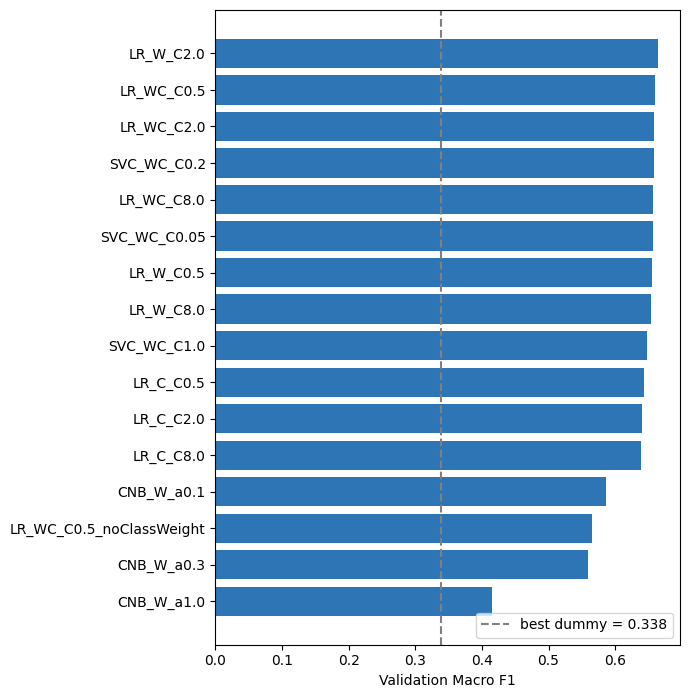

In [38]:
# Visual comparison on validation
plot_df = res_val[res_val["family"] != "Dummy"].sort_values("macro_f1")
fig, ax = plt.subplots(figsize=(7, 0.38 * len(plot_df) + 1))
ax.barh(plot_df["model"], plot_df["macro_f1"], color="#2E75B6")
dummy_best = res_val[res_val["family"] == "Dummy"]["macro_f1"].max()
ax.axvline(dummy_best, color="grey", ls="--", label=f"best dummy = {dummy_best:.3f}")
ax.set_xlabel("Validation Macro F1"); ax.legend(loc="lower right"); plt.tight_layout()
plt.savefig(OUT_DIR / "val_model_comparison.png", dpi=150); plt.show()

<div dir="rtl">

## ۱۰) آزمایش حذف فیلدهای متنی (Ablation)
آیا `advantages` و `disadvantages` واقعاً کمک می‌کنند؟ همان مدل (LR، ویژگی WC، همان `C`) را روی سه نسخه‌ی متن آموزش می‌دهیم.
(توجه: این فقط یک آزمایش تحلیلی روی val است؛ Split همان Split اصلی است.)

In [39]:
abl_rows = []
variants = {"body only": "text_body", "title + body": "text_title_body", "title + body + advantages + disadvantages (ours)": "text"}
for vname, vcol in variants.items():
    if vcol == "text":
        r = res_val[res_val["model"] == f"LR_WC_C{best_C}"].iloc[0]
        abl_rows.append({"text variant": vname, "macro_f1": r["macro_f1"], **{k: r[k] for k in [f"f1_{l}" for l in LABELS]}})
        continue
    f_, _ = fit_features(train[vcol], val[vcol], test[vcol], only_wc=True)
    clf = LogisticRegression(C=best_C, class_weight="balanced", max_iter=1000).fit(f_["WC"][0], y_tr)
    m = evaluate(y_va, clf.predict(f_["WC"][1]))
    abl_rows.append({"text variant": vname, "macro_f1": m["macro_f1"], **{k: m[k] for k in [f"f1_{l}" for l in LABELS]}})
abl = pd.DataFrame(abl_rows)
abl.to_csv(OUT_DIR / "ablation_text_fields_val.csv", index=False)
display(abl.round(4))

,text variant,macro_f1,f1_recommended,f1_not_recommended,f1_no_idea
0,body only,0.6084,0.8999,0.5630,0.3624
1,title + body,0.6572,0.9108,0.6418,0.4191
2,title + body + advantages + disadvantages (ours),0.6594,0.9110,0.6521,0.4152


<div dir="rtl">

## ۱۱) انتخاب مدل نهایی و تنظیم bias کلاس‌ها (فقط روی Val)
- مدل نهایی = بالاترین Macro F1 روی val (بین مدل‌های غیر Dummy).
- سپس یک عدد ثابت به امتیاز کلاس‌های `not_recommended` و `no_idea` اضافه می‌کنیم (نسبت به `recommended`) و روی val جست‌وجو می‌کنیم تا Macro F1 بیشتر شود.
- **قاعده‌ی از قبل مشخص:** bias فقط اگر روی val حداقل `BIAS_MIN_GAIN` (پیش‌فرض ۰٫۰۰۵) بهتر شود پذیرفته می‌شود. در حالت `RUN_ON="compare"` این مرحله **خاموش** است (val کوچک است و تنظیم bias نویز می‌شود؛ همه‌ی مدل‌ها با argmax ساده مقایسه می‌شوند).

In [40]:
cand = res_val[res_val["family"] != "Dummy"]
best_name = cand.iloc[0]["model"]
best = fitted[best_name]; best_clf, best_key = best["clf"], best["key"]
print(f"Selected on validation: {best_name}  (val Macro-F1 = {cand.iloc[0]['macro_f1']:.4f})")

S_va = get_scores_ordered(best_clf, feats[best_key][1])
scale = float(np.std(S_va)) or 1.0
grid = np.linspace(-1.0, 1.0, 21) * scale
base_f1 = macro_f1_int(y_va_i, S_va.argmax(1))

cands = []
for b1 in grid:
    for b2 in grid:
        bias = np.array([0.0, b1, b2])
        cands.append((macro_f1_int(y_va_i, (S_va + bias).argmax(1)), np.linalg.norm(bias), bias))
top = max(c[0] for c in cands)
near = [c for c in cands if c[0] >= top - 1e-4]
tuned_f1, _, bias_best = min(near, key=lambda c: c[1])        # among ties: smallest |bias|

ADOPT_BIAS = BIAS_MIN_GAIN is not None and (tuned_f1 - base_f1) >= BIAS_MIN_GAIN
bias_final = bias_best if ADOPT_BIAS else np.zeros(3)
print(f"val Macro-F1 raw = {base_f1:.4f} | with bias {np.round(bias_best, 3).tolist()} = {tuned_f1:.4f} -> adopt bias: {ADOPT_BIAS}")

Selected on validation: LR_W_C2.0  (val Macro-F1 = 0.6641)
val Macro-F1 raw = 0.6641 | with bias [0.0, -0.294, 0.0] = 0.6739 -> adopt bias: False


<div dir="rtl">

## ۱۲) ارزیابی نهایی روی Test (فقط یک‌بار)
از این نقطه به بعد **هیچ تنظیمی** بر اساس نتایج test انجام نمی‌شود.

In [41]:
S_te = get_scores_ordered(best_clf, feats[best_key][2])
pred_raw_i = S_te.argmax(1)
pred_fin_i = (S_te + bias_final).argmax(1)
pred_raw = np.array(LABELS)[pred_raw_i]
pred_fin = np.array(LABELS)[pred_fin_i]

# Floors on test (for reference only)
dummy_rows = []
for nm in ["Dummy_most_frequent", "Dummy_stratified"]:
    dclf = fitted[nm]["clf"]
    dummy_rows.append({"model": nm, **evaluate(y_te, dclf.predict(feats["W"][2]))})

ci, boot = cluster_bootstrap_ci(y_te_i, pred_fin_i, test["product_id"].values, n_boot=N_BOOT)
final_metrics = evaluate(y_te, pred_fin)
rows = dummy_rows + [{"model": f"{best_name} (raw)", **evaluate(y_te, pred_raw)},
                     {"model": f"{best_name} + bias [FINAL]" if ADOPT_BIAS else f"{best_name} [FINAL]", **final_metrics}]
res_test = pd.DataFrame(rows)
res_test.to_csv(OUT_DIR / "results_test.csv", index=False)
display(res_test.round(4))
print(f"\nFINAL TEST Macro F1 = {final_metrics['macro_f1']:.4f}   95% CI (cluster bootstrap over products, n={N_BOOT}): [{ci[0]:.4f}, {ci[1]:.4f}]")
print("\n", classification_report(y_te, pred_fin, labels=LABELS, digits=3, zero_division=0))

,model,macro_f1,macro_precision,macro_recall,accuracy,balanced_acc,f1_recommended,f1_not_recommended,f1_no_idea
0,Dummy_most_frequent,0.2946,0.2639,0.3333,0.7918,0.3333,0.8838,0.0000,0.0000
1,Dummy_stratified,0.3195,0.3193,0.3197,0.6481,0.3197,0.7948,0.0901,0.0735
2,LR_W_C2.0 (raw),0.6696,0.6611,0.6789,0.8488,0.6789,0.9325,0.6891,0.3872
3,LR_W_C2.0 [FINAL],0.6696,0.6611,0.6789,0.8488,0.6789,0.9325,0.6891,0.3872



FINAL TEST Macro F1 = 0.6696   95% CI (cluster bootstrap over products, n=1000): [0.6400, 0.6968]

                  precision    recall  f1-score   support

    recommended      0.941     0.924     0.932      1681
not_recommended      0.669     0.710     0.689       231
        no_idea      0.373     0.403     0.387       211

       accuracy                          0.849      2123
      macro avg      0.661     0.679     0.670      2123
   weighted avg      0.855     0.849     0.852      2123



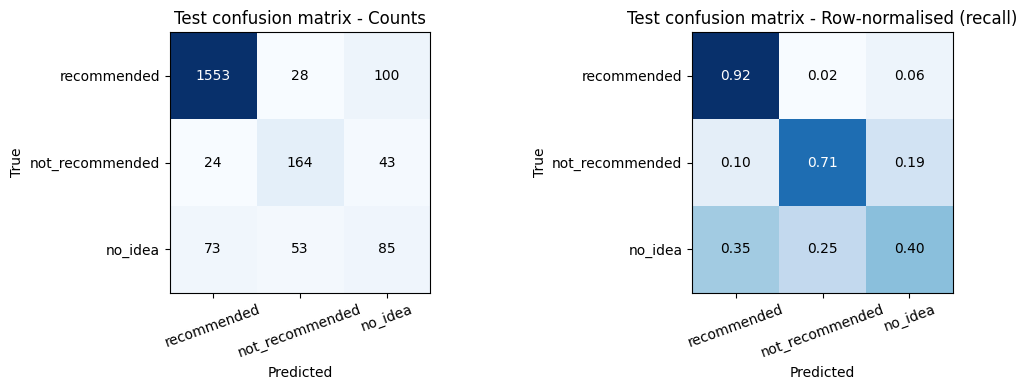

In [42]:
cm = confusion_matrix(y_te, pred_fin, labels=LABELS)
cm_norm = cm / cm.sum(1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, M, title, fmt in [(axes[0], cm, "Counts", "{:d}"), (axes[1], cm_norm, "Row-normalised (recall)", "{:.2f}")]:
    im = ax.imshow(M, cmap="Blues")
    ax.set_xticks(range(3)); ax.set_xticklabels(LABELS, rotation=20); ax.set_yticks(range(3)); ax.set_yticklabels(LABELS)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"Test confusion matrix - {title}")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", color="white" if M[i, j] > M.max() * 0.6 else "black")
plt.tight_layout(); plt.savefig(OUT_DIR / "test_confusion_matrix.png", dpi=150); plt.show()

# save test predictions (needed for paired comparison with ParsBERT / FaBERT / XLM-R later)
pred_df = test[["id", "product_id", "label"]].rename(columns={"label": "y_true"}).copy()
pred_df["y_pred_raw"] = pred_raw; pred_df["y_pred_final"] = pred_fin
for i, l in enumerate(LABELS):
    pred_df[f"score_{l}"] = S_te[:, i]
pred_df.to_parquet(OUT_DIR / "test_predictions_baseline.parquet", index=False)

<div dir="rtl">

## ۱۳) تحلیل خطا (Failure Analysis)
مدل کجا و چرا اشتباه می‌کند؟

In [43]:
# 1) Which words push each class? (only for linear models, word features)
clf = best_clf
if hasattr(clf, "coef_") or hasattr(clf, "feature_log_prob_"):
    W = clf.coef_ if hasattr(clf, "coef_") else clf.feature_log_prob_
    order = [list(clf.classes_).index(l) for l in LABELS]
    W = W[order]
    word_vec = vecs[best_key][0] if best_key in ("W", "WC") else None
    if word_vec is not None:
        names = np.array(word_vec.get_feature_names_out())
        n_word = len(names)
        top = {}
        for i, l in enumerate(LABELS):
            w = W[i, :n_word]
            top[l] = names[np.argsort(-w)[:25]]
        display(pd.DataFrame(top))
else:
    print("model has no linear weights; skipping")

,recommended,not_recommended,no_idea
0,عالی,اصلا,ولی
1,عالیه,نخرید,معمولی
2,مزایا,افتضاح,نیست
3,خوب,بی کیفیت,اما
4,خوبه,تقلبی,خوب خیلی
5,زیبا,هیچ,زیاد
6,مناسب,نمیکنم,معمولیه
7,بهترین,متاسفم,پلاستیکی
8,عالیی,مرجوع,نکردم
9,با کیفیت,حتی,خورده


In [44]:
# 2) Error table on test
err = test[["id", "product_id", "label", "text", "rate", "n_words", "sub_category"]].copy()
err["pred"] = pred_fin
err["correct"] = err["label"] == err["pred"]
sc = S_te + bias_final
sc = sc - sc.max(1, keepdims=True)
prob = np.exp(sc) / np.exp(sc).sum(1, keepdims=True)
err["confidence"] = prob.max(1).round(3)
print("Overall test accuracy: %.4f | error rate: %.4f" % (err["correct"].mean(), 1 - err["correct"].mean()))

pairs = (err[~err["correct"]].groupby(["label", "pred"]).size().sort_values(ascending=False).to_frame("n_errors"))
display(pairs)

# 3) Error rate by rate / length / category
if err["rate"].notna().any():
    print("\nError rate by user rate:")
    display(err.groupby("rate")["correct"].agg(n="size", error_rate=lambda x: round(1 - x.mean(), 3)).T)

err["len_bucket"] = pd.cut(err["n_words"], [0, 2, 5, 10, 20, 50, 10_000], labels=["1-2", "3-5", "6-10", "11-20", "21-50", "50+"])
print("\nError rate by text length (words):")
display(err.groupby("len_bucket", observed=True)["correct"].agg(n="size", error_rate=lambda x: round(1 - x.mean(), 3)).T)

def macro_f1_present(g):
    labs = [l for l in LABELS if (g["label"] == l).any()]
    return f1_score(g["label"], g["pred"], labels=labs, average="macro", zero_division=0) if labs else np.nan
from sklearn.metrics import f1_score
cat = pd.DataFrame([{"sub_category": k, "n": len(g), "accuracy": g["correct"].mean(),
                     "macro_f1(present classes)": macro_f1_present(g)} for k, g in err.groupby("sub_category")]).set_index("sub_category")
print("\nBy sub_category (n >= 25):")
display(cat[cat["n"] >= 25].sort_values("n", ascending=False).round(3))

Overall test accuracy: 0.8488 | error rate: 0.1512


n_errors
label           pred                     
recommended     no_idea               100
no_idea         recommended            73
                not_recommended        53
not_recommended no_idea                43
recommended     not_recommended        28
not_recommended recommended            24


Error rate by user rate:


rate,0.25,0.50,0.60,0.85,1.00,1.15,1.20,1.25,1.30,1.40,1.50,1.60,1.75,1.80,1.90,1.95,2.00,2.10,2.20,2.25,2.30,2.40,2.45,2.50,2.55,2.60,2.65,2.75,2.80,2.85,...,3.45,3.50,3.55,3.60,3.65,3.70,3.75,3.80,3.85,3.90,4.00,4.05,4.10,4.15,4.20,4.25,4.30,4.35,4.40,4.45,4.50,4.55,4.60,4.65,4.70,4.75,4.80,4.85,4.90,5.00
n,1.0,1.0,1.0,1.0,135.00,1.0,3.000,3.000,1.0,1.0,1.0,1.0,3.000,1.0,2.0,1.0,44.000,2.0,4.0,4.00,1.0,5.0,1.0,2.0,1.0,5.0,2.0,5.0,2.0,1.0,...,1.0,17.000,1.0,9.000,5.0,7.000,13.000,14.000,2.0,4.00,328.000,2.0,4.0,1.0,15.000,15.0,10.0,4.0,13.0,3.0,23.00,1.0,17.0,3.0,6.0,18.0,16.0,2.0,1.0,776.000
error_rate,0.0,0.0,0.0,0.0,0.23,0.0,0.667,0.333,1.0,1.0,0.0,0.0,0.667,1.0,0.5,0.0,0.523,0.5,0.5,0.25,1.0,0.8,0.0,0.5,0.0,0.2,0.0,0.2,0.5,1.0,...,0.0,0.235,0.0,0.444,0.0,0.143,0.154,0.357,0.5,0.25,0.162,0.0,0.0,0.0,0.067,0.2,0.0,0.0,0.0,0.0,0.13,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.045



Error rate by text length (words):


len_bucket,1-2,3-5,6-10,11-20,21-50,50+
n,6.0,41.000,208.000,355.000,774.000,739.000
error_rate,0.0,0.073,0.091,0.099,0.154,0.196



By sub_category (n >= 25):


,n,accuracy,macro_f1(present classes)
sub_category,,,
beauty,694,0.833,0.646
clothe,493,0.842,0.697
book & stationary & art,404,0.879,0.645
toys and kids,328,0.851,0.673
rural goods,150,0.860,0.648
travel,54,0.852,0.765


In [45]:
# 4) Read real mistakes (the best material for the failure-analysis slide)
rng = np.random.default_rng(SEED)
for (t_lab, p_lab), n_err in pairs.head(4)["n_errors"].items():
    sub = err[(err["label"] == t_lab) & (err["pred"] == p_lab)]
    print(f"\n=== true = {t_lab}  |  predicted = {p_lab}   ({n_err} errors) ===")
    show = sub.sample(min(6, len(sub)), random_state=SEED)
    for _, r in show.iterrows():
        print(f"- [id={r['id']}] rate={r['rate']} conf={r['confidence']}  ->  {r['text'][:200]}")

err[~err["correct"]].sort_values("confidence", ascending=False).to_csv(OUT_DIR / "error_analysis_test.csv", index=False)
print("\nsaved all test errors (sorted by confidence) ->", OUT_DIR / "error_analysis_test.csv")


=== true = recommended  |  predicted = no_idea   (100 errors) ===
- [id=44713803] rate=5.0 conf=0.516  ->  گج مو . گچ مو عالیه ولی بجای رنگ آبی رنگ قرمز برام فرستادن لطفا در بسته بندی دقت کنید . مزایا: مو رو رنگ میکنه | جنس عالی . معایب: به جای رنگ ابی قرمز فرستادن
- [id=44020961] rate=4.0 conf=0.482  ->  خوب بود ولی زدن سنجاق ها کنار هم مشکل بود . خوب بود بد نبود ولی بزرگ بود زدن سنجاق ها کنار هم مشکل بود
- [id=49816893] rate=4.0 conf=0.568  ->  بی دقتی فروشگاه . یه دمپایی با طرح دابل نایکی فرستاده فروشنده.. حالا کیفیت و ایناش خوبه مشکلی نیست اما خب طرح آدیداس کجا و این کجا 😂 سری بعد دقت کنید شاید یه مشتری دیگه براش مهم باشه..
- [id=52415135] rate=4.0 conf=0.478  ->  کفش کالج . من شماره پام در اکثر برندها، 39 هستش و معدود کفش با سایز 38 و یا 38/5 دارم. دو جفت از این کفش رو خریدم (38 و 39) تا ببینم کدوم اندازه‌اش برای من مناسبه. انتخابم سایز 38 بود و حین راه رفتن س
- [id=17772993] rate=3.0 conf=0.765  ->  برا کاردستی خوبه . برا کاردستی خوبه ولی بشته بندی بدی برام اوردن . مزایا: به درد

<div dir="rtl">

## ۱۴) منحنی یادگیری
با ۱۰٪ / ۲۵٪ / ۵۰٪ / ۱۰۰٪ محصولات train، همان مدل را آموزش می‌دهیم. اگر منحنی هنوز رو به بالاست، یعنی داده‌ی بیشتر (یا مدل قوی‌تر) کمک می‌کند. (ویژگی‌ها از vocabulary کل train ساخته شده‌اند.)

,train_fraction,n_train,val_macro_f1
0,0.10,1037,0.5258
1,0.25,2742,0.6352
2,0.50,5231,0.6395
3,1.00,10559,0.6641


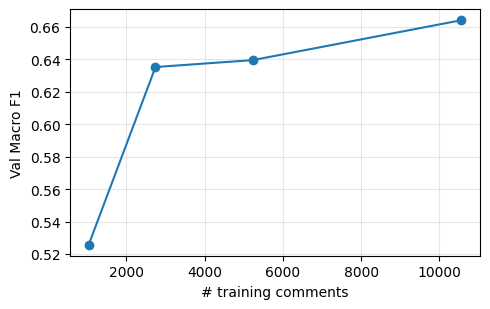

In [46]:
if RUN_LEARNING_CURVE and not QUICK:
    rng = np.random.default_rng(SEED)
    pids = train["product_id"].unique(); rng.shuffle(pids)
    Xtr_full = feats[best_key][0]; Xva_full = feats[best_key][1]
    lc = []
    for frac in [0.1, 0.25, 0.5, 1.0]:
        sel = set(pids[: max(1, int(len(pids) * frac))])
        mask = train["product_id"].isin(sel).values
        m = clone(best_clf).fit(Xtr_full[mask], y_tr[mask])
        pr = m.predict(Xva_full)
        lc.append({"train_fraction": frac, "n_train": int(mask.sum()), "val_macro_f1": evaluate(y_va, pr)["macro_f1"]})
    lc = pd.DataFrame(lc); display(lc.round(4)); lc.to_csv(OUT_DIR / "learning_curve_val.csv", index=False)
    plt.figure(figsize=(5, 3.2)); plt.plot(lc["n_train"], lc["val_macro_f1"], marker="o")
    plt.xlabel("# training comments"); plt.ylabel("Val Macro F1"); plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(OUT_DIR / "learning_curve.png", dpi=150); plt.show()
else:
    print("skipped")

<div dir="rtl">

## ۱۵) ذخیره‌ی مدل و ساخت تابع `predict_recommendation(text)`
این همان تابعی است که در قرارداد پروژه تعریف کردیم. بعد از ذخیره، یک **تست سازگاری** انجام می‌شود: پیش‌بینی تابع باید دقیقاً با پیش‌بینی نوت‌بوک یکی باشد.

In [47]:
bundle = {"vectorizers": vecs[best_key], "clf": best_clf, "bias": bias_final, "labels": LABELS,
          "feature_key": best_key, "model_name": best_name}
joblib.dump(bundle, MODEL_DIR / "baseline_bundle.joblib")

PREDICTOR_SRC = r'''
from pathlib import Path

import joblib
import numpy as np
from scipy.sparse import hstack

from persian_text import LABELS, clean_text  # noqa: F401  (tfidf_preprocess is needed to unpickle the vectorizers)
import persian_text  # noqa: F401

_BASE = Path(__file__).resolve().parent.parent / "models"


def _default_path():
    for sub in ("full", "compare"):
        p = _BASE / sub / "baseline_bundle.joblib"
        if p.exists():
            return p
    return _BASE / "full" / "baseline_bundle.joblib"
_CACHE = {}


def _load(path=None):
    path = str(path or _default_path())
    if path not in _CACHE:
        _CACHE[path] = joblib.load(path)
    return _CACHE[path]


def _scores(clf, X):
    s = clf.decision_function(X) if hasattr(clf, "decision_function") else clf.predict_log_proba(X)
    order = [list(clf.classes_).index(l) for l in LABELS]
    return s[:, order]


def predict_recommendation_batch(texts, model_path=None):
    b = _load(model_path)
    cleaned = [clean_text(t) for t in texts]
    mats = [v.transform(cleaned) for v in b["vectorizers"]]
    X = mats[0] if len(mats) == 1 else hstack(mats).tocsr()
    idx = (_scores(b["clf"], X) + b["bias"]).argmax(1)
    return [LABELS[i] for i in idx]


def predict_recommendation(text, model_path=None):
    return predict_recommendation_batch([text], model_path)[0]
'''
(SRC_DIR / "baseline_predictor.py").write_text(PREDICTOR_SRC, encoding="utf-8")

import baseline_predictor
importlib.reload(baseline_predictor)
from baseline_predictor import predict_recommendation, predict_recommendation_batch

# ---- consistency test: module output must equal the notebook output
sample_idx = np.random.default_rng(SEED).choice(len(test), size=min(300, len(test)), replace=False)
mod_pred = predict_recommendation_batch(test["text"].iloc[sample_idx].tolist(), MODEL_DIR / "baseline_bundle.joblib")
assert list(mod_pred) == list(pred_fin[sample_idx]), "predictor module disagrees with notebook predictions!"
print("consistency test passed on", len(sample_idx), "test comments")

for t in ["عالی بود، کیفیتش فوق‌العاده‌ست و پیشنهاد می‌کنم", "افتضاح بود، اصلا نخرید پولتون هدر میره", "نمیدونم والا، معمولی بود"]:
    print(f"{predict_recommendation(t, MODEL_DIR / 'baseline_bundle.joblib'):>16}  <-  {t}")

consistency test passed on 300 test comments
     recommended  <-  عالی بود، کیفیتش فوق‌العاده‌ست و پیشنهاد می‌کنم
 not_recommended  <-  افتضاح بود، اصلا نخرید پولتون هدر میره
         no_idea  <-  نمیدونم والا، معمولی بود


<div dir="rtl">

## ۱۶) خلاصه‌ی نهایی

In [48]:
summary = {
    "n_comments_after_cleaning": int(len(df)),
    "split_rows": {s: int((df.split == s).sum()) for s in ("train", "val", "test")},
    "split_products": {s: int(df.loc[df.split == s, "product_id"].nunique()) for s in ("train", "val", "test")},
    "run_on": RUN_ON, "selected_model": best_name, "features": best_key, "bias_adopted": bool(ADOPT_BIAS), "bias": [round(float(b), 4) for b in bias_final],
    "val_macro_f1_selected": float(cand.iloc[0]["macro_f1"]),
    "test_macro_f1": float(final_metrics["macro_f1"]), "test_macro_f1_ci95": [float(ci[0]), float(ci[1])],
    "test_f1_per_class": {l: float(final_metrics[f"f1_{l}"]) for l in LABELS},
    "best_dummy_test_macro_f1": float(max(r["macro_f1"] for r in dummy_rows)),
    "files": {"split": str(SPLIT_DIR / f"data_split_{RUN_ON}.parquet"), "model": str(MODEL_DIR / "baseline_bundle.joblib"),
              "predictor": str(SRC_DIR / "baseline_predictor.py"), "text_utils": str(SRC_DIR / "persian_text.py"),
              "test_predictions": str(OUT_DIR / "test_predictions_baseline.parquet")},
}
json.dump(summary, open(OUT_DIR / "summary.json", "w"), ensure_ascii=False, indent=2)
print(json.dumps(summary, ensure_ascii=False, indent=2))
print("\nAll outputs are in:", WORK_DIR.resolve())

{
  "n_comments_after_cleaning": 14956,
  "split_rows": {
    "train": 10559,
    "val": 2274,
    "test": 2123
  },
  "split_products": {
    "train": 6311,
    "val": 1280,
    "test": 1276
  },
  "run_on": "full",
  "selected_model": "LR_W_C2.0",
  "features": "W",
  "bias_adopted": false,
  "bias": [
    0.0,
    0.0,
    0.0
  ],
  "val_macro_f1_selected": 0.6641101046865029,
  "test_macro_f1": 0.6695906943056767,
  "test_macro_f1_ci95": [
    0.6400045414109304,
    0.6968041022960012
  ],
  "test_f1_per_class": {
    "recommended": 0.9324527169018313,
    "not_recommended": 0.6890756302521008,
    "no_idea": 0.38724373576309795
  },
  "best_dummy_test_macro_f1": 0.319479570933246,
  "files": {
    "split": "/content/drive/MyDrive/QBC13_final/part3_classifier/splits/data_split_full.parquet",
    "model": "/content/drive/MyDrive/QBC13_final/part3_classifier/models/full/baseline_bundle.joblib",
    "predictor": "/content/drive/MyDrive/QBC13_final/part3_classifier/src/baseline_predi